# Assignment 5 — Word2Vec, fastText, Doc2Vec + K-Means Clustering (IndicCorp v2, Hindi)

**Corpus:** same Hindi (`hin_Deva`) IndicCorp v2 corpus of **1,000,000 sentences**, using the
**same train / dev / test splits** built in the first assignment and reused in Assignment 4.

This notebook:

1. Reloads the exact train / dev / test splits (`data/train_pool.txt`, `data/dev.txt`,
   `data/test.txt`), rebuilding them from scratch with the identical pipeline if they aren't found
   locally.
2. Trains three embedding models on the training data, following gensim's official tutorials:
   - **Word2Vec** (`gensim.models.Word2Vec`) — [tutorial](https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html)
   - **fastText** (`gensim.models.FastText`) — [tutorial](https://radimrehurek.com/gensim/auto_examples/tutorials/run_fasttext.html)
   - **Doc2Vec** (`gensim.models.doc2vec.Doc2Vec`) — [tutorial](https://radimrehurek.com/gensim/auto_examples/tutorials/run_doc2vec_lee.html)
3. Runs **K-Means clustering** on the Word2Vec word vectors, and for each cluster reports the
   **20 words closest to the cluster centroid**.
4. Represents every dev/test sentence as a vector two ways — **(a)** averaged word embeddings
   (from Word2Vec and, separately, from fastText) and **(b)** inferred Doc2Vec embeddings — and
   for each dev/test sentence finds its **closest training sentence** by cosine similarity under
   each representation.

> **Note on runtime:** this notebook is provided as the assignment deliverable (code only) and is
> **not executed here**. Training Word2Vec/fastText/Doc2Vec on 1,000,000 sentences, and especially
> the exhaustive nearest-sentence search over the full training set, can take a long time — see
> `SAMPLE_TRAIN_SIZE` in Section 0 for a faster sanity-check pass, and `MAX_TRAIN_SENTENCES_FOR_NN`
> in Section 6 to cap the pool searched for nearest neighbors.


## 0. Setup — imports and config

In [1]:

!pip install -q gensim scikit-learn numpy pandas tqdm matplotlib


In [2]:

import os
import re
import random
import itertools
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

random.seed(42)
np.random.seed(42)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

# Embedding dimensionality (shared across Word2Vec / fastText / Doc2Vec for fair comparison)
EMBED_DIM   = 100
WINDOW      = 5
MIN_COUNT   = 5
EPOCHS      = 10
NUM_WORKERS = os.cpu_count() or 4

# K-Means
N_CLUSTERS = 20
WORDS_PER_CLUSTER = 20

# If you just want a fast sanity-check run before committing to the full 1M-sentence
# training set, set SAMPLE_TRAIN_SIZE to e.g. 100_000. Set to None to use the FULL train split.
SAMPLE_TRAIN_SIZE = 100_000


## 1. Load the same train / dev / test splits from the previous assignments

Reuses `data/train_pool.txt`, `data/dev.txt`, `data/test.txt` exactly as in Assignments 1 and 4.
If they're missing, they're rebuilt with the identical IndicCorp v2 streaming + sentence
tokenization + length-stratified split procedure, so this notebook is self-contained.


In [3]:

train_pool_path = DATA_DIR / "train_pool.txt"
dev_path        = DATA_DIR / "dev.txt"
test_path       = DATA_DIR / "test.txt"

def read_lines(path):
    with open(path, "r", encoding="utf-8") as f:
        return [line.rstrip("\n") for line in f if line.strip()]

if train_pool_path.exists() and dev_path.exists() and test_path.exists():
    print("Found existing splits from the previous assignments — loading them.")
    train_sentences = read_lines(train_pool_path)
    dev_sentences   = read_lines(dev_path)
    test_sentences  = read_lines(test_path)
else:
    print("Splits not found locally — rebuilding from IndicCorp v2 (same procedure as before).")

    LANGUAGE_SPLIT = "hin_Deva"
    LANGUAGE_NAME  = "Hindi"
    LANG_ISO       = "hi"

    MAX_TRAIN_SIZE = 1_000_000
    DEV_SIZE       = 1_000
    TEST_SIZE      = 1_000
    TARGET_SENTENCES = MAX_TRAIN_SIZE + DEV_SIZE + TEST_SIZE
    PARAGRAPH_SAFETY_MARGIN = 1.4

    from datasets import load_dataset

    def stream_paragraphs(language_split, n_target):
        ds = load_dataset(
            "ai4bharat/IndicCorpV2",
            "indiccorp_v2",
            split=language_split,
            streaming=True,
        )
        paragraphs = []
        n_pull = int(n_target * PARAGRAPH_SAFETY_MARGIN)
        for ex in tqdm(ds, total=n_pull, desc=f"Streaming {language_split}"):
            text = ex["text"].strip()
            if text:
                paragraphs.append(text)
            if len(paragraphs) >= n_pull:
                break
        return paragraphs

    raw_paragraphs = stream_paragraphs(LANGUAGE_SPLIT, TARGET_SENTENCES)
    print(f"Pulled {len(raw_paragraphs):,} paragraphs for {LANGUAGE_NAME}")

    try:
        from indicnlp.tokenize import sentence_tokenize as indic_sent_tok
        HAVE_INDIC_NLP = True
        print("Using indic-nlp-library sentence tokenizer")
    except Exception as e:
        HAVE_INDIC_NLP = False
        print("indic-nlp-library unavailable, using regex fallback:", e)

    _SENT_SPLIT_RE = re.compile(r"(?<=[।॥.!?])\s+")

    def sentence_tokenize(paragraph, lang_iso="hi"):
        if HAVE_INDIC_NLP:
            try:
                sents = indic_sent_tok.sentence_split(paragraph, lang=lang_iso)
                sents = [s.strip() for s in sents if s.strip()]
                if sents:
                    return sents
            except Exception:
                pass
        sents = _SENT_SPLIT_RE.split(paragraph)
        return [s.strip() for s in sents if s.strip()]

    def clean_sentence(s):
        return re.sub(r"\s+", " ", s).strip()

    MIN_SENT_LEN_CHARS = 5
    MAX_SENT_LEN_CHARS = 800

    all_sentences = []
    seen = set()
    for para in tqdm(raw_paragraphs, desc="Sentence-tokenizing"):
        for sent in sentence_tokenize(para, LANG_ISO):
            sent = clean_sentence(sent)
            if not (MIN_SENT_LEN_CHARS <= len(sent) <= MAX_SENT_LEN_CHARS):
                continue
            if sent in seen:
                continue
            seen.add(sent)
            all_sentences.append(sent)
        if len(all_sentences) >= TARGET_SENTENCES:
            break

    print(f"Collected {len(all_sentences):,} unique sentences (target: {TARGET_SENTENCES:,})")

    def word_len(s):
        return len(s.split())

    lengths = np.array([word_len(s) for s in all_sentences])
    df = pd.DataFrame({"sentence": all_sentences, "length": lengths})

    N_BINS = 10
    df["bin"] = pd.qcut(df["length"], q=N_BINS, duplicates="drop")

    def stratified_sample(frame, n_total, n_bins_col="bin", seed=42):
        bins = frame[n_bins_col].cat.categories
        picks = []
        bin_sizes = frame.groupby(n_bins_col, observed=True).size()
        proportions = bin_sizes / bin_sizes.sum()
        raw_alloc = proportions * n_total
        alloc = np.floor(raw_alloc).astype(int)
        shortfall = n_total - alloc.sum()
        remainder_order = (raw_alloc - alloc).sort_values(ascending=False).index
        for b in remainder_order[:shortfall]:
            alloc[b] += 1
        for b in bins:
            sub = frame[frame[n_bins_col] == b]
            k = min(alloc.get(b, 0), len(sub))
            chosen = sub.sample(n=k, random_state=seed)
            picks.append(chosen)
        sampled = pd.concat(picks).sample(frac=1.0, random_state=seed)
        remaining = frame.drop(sampled.index)
        return sampled, remaining

    test_df, pool_df = stratified_sample(df, TEST_SIZE, seed=42)
    dev_df,  pool_df = stratified_sample(pool_df, DEV_SIZE, seed=43)
    train_pool_df = pool_df.sample(frac=1.0, random_state=44).reset_index(drop=True)

    def write_lines(path, sentences):
        with open(path, "w", encoding="utf-8") as f:
            for s in sentences:
                f.write(s + "\n")

    write_lines(train_pool_path, train_pool_df["sentence"].tolist())
    write_lines(dev_path,        dev_df["sentence"].tolist())
    write_lines(test_path,       test_df["sentence"].tolist())

    train_sentences = train_pool_df["sentence"].tolist()
    dev_sentences   = dev_df["sentence"].tolist()
    test_sentences  = test_df["sentence"].tolist()

if SAMPLE_TRAIN_SIZE is not None:
    train_sentences = train_sentences[:SAMPLE_TRAIN_SIZE]

print(f"train: {len(train_sentences):,} | dev: {len(dev_sentences):,} | test: {len(test_sentences):,}")


Splits not found locally — rebuilding from IndicCorp v2 (same procedure as before).


Streaming hin_Deva:   0%|          | 0/1402800 [00:00<?, ?it/s]

Pulled 1,402,800 paragraphs for Hindi
Using indic-nlp-library sentence tokenizer


Sentence-tokenizing:   0%|          | 0/1402800 [00:00<?, ?it/s]

Collected 1,002,003 unique sentences (target: 1,002,000)
train: 100,000 | dev: 1,000 | test: 1,000


## 2. Tokenize sentences into word lists

All three gensim models expect a list of tokenized sentences (`List[List[str]]`). We reuse simple
whitespace tokenization, consistent with the earlier assignments.


In [4]:

def word_tokenize(sentence):
    return sentence.strip().split()

train_tokens = [word_tokenize(s) for s in tqdm(train_sentences, desc="Tokenizing train")]
dev_tokens   = [word_tokenize(s) for s in tqdm(dev_sentences,   desc="Tokenizing dev")]
test_tokens  = [word_tokenize(s) for s in tqdm(test_sentences,  desc="Tokenizing test")]

print(f"Example tokenized sentence: {train_tokens[0]}")


Tokenizing train:   0%|          | 0/100000 [00:00<?, ?it/s]

Tokenizing dev:   0%|          | 0/1000 [00:00<?, ?it/s]

Tokenizing test:   0%|          | 0/1000 [00:00<?, ?it/s]

Example tokenized sentence: ['आरोपियों', 'के', 'नाम', 'तारकभादूर', 'सोनार', '(35),', 'फिरोज', 'खान', '(27)', 'है', 'जबकि', '55', 'महिला', 'के', 'नाम', 'का', 'खुलासा', 'नहीं', 'हुआ', 'है।']


## 3. Train Word2Vec

Following the [gensim Word2Vec tutorial](https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html):
a skip-gram/CBOW model trained directly on our tokenized sentences via `gensim.models.Word2Vec`.
We use the `sg=1` (skip-gram) architecture, which tends to work better for smaller/morphologically
rich corpora, but CBOW (`sg=0`) is noted as an easy toggle.


In [5]:

from gensim.models import Word2Vec

w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=EMBED_DIM,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=NUM_WORKERS,
    sg=1,            # skip-gram (set to 0 for CBOW)
    epochs=EPOCHS,
    seed=42,
)

print(f"Word2Vec vocabulary size: {len(w2v_model.wv):,}")
w2v_model.save(str(MODELS_DIR / "word2vec_hindi.model"))
print("Saved:", MODELS_DIR / "word2vec_hindi.model")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Word2Vec vocabulary size: 18,917
Saved: models/word2vec_hindi.model


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


In [6]:

# Quick sanity check: nearest neighbours of a few frequent words
sample_words = [w for w, _ in Counter(itertools.chain.from_iterable(train_tokens)).most_common(20)]
for w in sample_words[:5]:
    if w in w2v_model.wv:
        neighbours = w2v_model.wv.most_similar(w, topn=5)
        print(f"{w!r} -> {neighbours}")


'के' -> [('भेजा.', 0.6720041632652283), ('बुद्धिजीवी', 0.640929102897644), ('नवी', 0.6236382126808167), ('चुना।', 0.6226192116737366), ('ज्वैलर्स', 0.6223483681678772)]
'में' -> [('मे', 0.6600344777107239), ('घटना,', 0.6219075322151184), ('के', 0.6027853488922119), ('मूलत:', 0.5952167510986328), ('कुछेक', 0.5945178866386414)]
'की' -> [('पीडि़तों', 0.6483731269836426), ('जतायी', 0.6417103409767151), ('टाली', 0.6325064301490784), ('रखी।', 0.6204133033752441), ('बांटी', 0.618263304233551)]
'को' -> [('काे', 0.6606077551841736), ('उसे', 0.6086434721946716), ('इन्हें', 0.6054834723472595), ('इसे', 0.597757875919342), ('उन्हें', 0.5942648649215698)]
'से' -> [('उससे', 0.6133832335472107), ('नूडल्स', 0.5719462037086487), ('वाद-विवाद', 0.5668032169342041), ('लगेगी।', 0.5605641603469849), ('467', 0.5579277873039246)]


## 4. Train fastText

Following the [gensim fastText tutorial](https://radimrehurek.com/gensim/auto_examples/tutorials/run_fasttext.html).
fastText augments Word2Vec by also learning embeddings for **character n-grams**, which is
particularly useful for a morphologically rich language like Hindi (it lets the model produce
reasonable vectors for out-of-vocabulary / rare inflected forms via their subword pieces).


In [7]:

from gensim.models import FastText

fasttext_model = FastText(
    sentences=train_tokens,
    vector_size=EMBED_DIM,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=NUM_WORKERS,
    sg=1,
    epochs=EPOCHS,
    min_n=3,          # min character n-gram length
    max_n=6,           # max character n-gram length
    seed=42,
)

print(f"fastText vocabulary size: {len(fasttext_model.wv):,}")
fasttext_model.save(str(MODELS_DIR / "fasttext_hindi.model"))
print("Saved:", MODELS_DIR / "fasttext_hindi.model")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_fl

fastText vocabulary size: 18,917
Saved: models/fasttext_hindi.model


In [8]:

# fastText can embed OOV words via subword n-grams -- demonstrate on a word not seen in training
oov_candidates = [w for w in sample_words[:3]]
for w in oov_candidates:
    if w in fasttext_model.wv:
        neighbours = fasttext_model.wv.most_similar(w, topn=5)
        print(f"{w!r} -> {neighbours}")


'के' -> [('बशीरहाट', 0.6273983120918274), ('BSNL', 0.6202538013458252), ('पीओके', 0.6152250170707703), ('पखवाड़े', 0.6150413751602173), ('GORAKHPUR:', 0.6144537329673767)]
'में' -> [('मेंं', 0.7672092318534851), ('मेंहदी', 0.7257870435714722), ('में-', 0.7125490307807922), ('मे', 0.7095135450363159), ('में"', 0.7080156207084656)]
'की' -> [('इनकी', 0.6511444449424744), ('रखी.', 0.631635308265686), ('रोकी', 0.6168926358222961), ('बढती', 0.6140028238296509), ('रखी।', 0.6124143600463867)]


## 5. Train Doc2Vec

Following the [gensim Doc2Vec (Lee corpus) tutorial](https://radimrehurek.com/gensim/auto_examples/tutorials/run_doc2vec_lee.html):
each training sentence is wrapped in a `TaggedDocument` with a unique integer tag, then a
`Doc2Vec` model (distributed memory, `dm=1`) is trained to jointly learn word vectors and
paragraph/sentence vectors. After training we can `infer_vector` on new (dev/test) sentences.


In [9]:

from gensim.models.doc2vec import Doc2Vec, TaggedDocument

train_tagged_docs = [
    TaggedDocument(words=toks, tags=[str(i)]) for i, toks in enumerate(train_tokens)
]

doc2vec_model = Doc2Vec(
    documents=train_tagged_docs,
    vector_size=EMBED_DIM,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=NUM_WORKERS,
    dm=1,             # distributed memory (set to 0 for DBOW)
    epochs=EPOCHS,
    seed=42,
)

print(f"Doc2Vec vocabulary size: {len(doc2vec_model.wv):,}")
print(f"Number of trained document vectors: {len(doc2vec_model.dv):,}")
doc2vec_model.save(str(MODELS_DIR / "doc2vec_hindi.model"))
print("Saved:", MODELS_DIR / "doc2vec_hindi.model")


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Doc2Vec vocabulary size: 18,917
Number of trained document vectors: 100,000
Saved: models/doc2vec_hindi.model


In [10]:

# Sanity check: a training sentence should be its own (near-)top match among training doc vectors
sample_idx = 0
inferred = doc2vec_model.infer_vector(train_tokens[sample_idx])
most_similar_docs = doc2vec_model.dv.most_similar([inferred], topn=3)
print("Query sentence:", train_sentences[sample_idx])
print("Most similar training doc-vector tags:", most_similar_docs)


Query sentence: आरोपियों के नाम तारकभादूर सोनार (35), फिरोज खान (27) है जबकि 55 महिला के नाम का खुलासा नहीं हुआ है।
Most similar training doc-vector tags: [('0', 0.8065165281295776), ('97928', 0.757341206073761), ('48850', 0.7536405324935913)]


## 6. K-Means clustering of word vectors

We cluster the **Word2Vec** word vectors (one point per vocabulary word) into `N_CLUSTERS = 20`
clusters with scikit-learn's `KMeans`, then for each cluster report the **20 words whose
embeddings are closest to the cluster centroid** (by Euclidean distance in embedding space, which
is what `KMeans` itself optimizes).


In [11]:

from sklearn.cluster import KMeans

w2v_vocab = list(w2v_model.wv.index_to_key)
w2v_vectors = np.array([w2v_model.wv[w] for w in w2v_vocab], dtype=np.float32)
print(f"Clustering {len(w2v_vocab):,} word vectors of dim {w2v_vectors.shape[1]} into {N_CLUSTERS} clusters ...")

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(w2v_vectors)

print("Cluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())


Clustering 18,917 word vectors of dim 100 into 20 clusters ...


/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/Caskroom/miniconda/base/lib/python3.13/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invali

Cluster sizes:
0      648
1      697
2      969
3     1049
4      605
5     1404
6      862
7      702
8     1021
9     2496
10     676
11     625
12    1039
13    1360
14     792
15    1030
16    1010
17     669
18     630
19     633
Name: count, dtype: int64


In [12]:

def closest_words_to_centroids(vectors, words, labels, centroids, k=WORDS_PER_CLUSTER):
    # \"\"\"For every cluster, return the k words whose vectors are nearest (Euclidean) to
    # that cluster's centroid.\"\"\"
    cluster_top_words = {}
    for c in range(centroids.shape[0]):
        idxs = np.where(labels == c)[0]
        if len(idxs) == 0:
            cluster_top_words[c] = []
            continue
        member_vectors = vectors[idxs]
        dists = np.linalg.norm(member_vectors - centroids[c], axis=1)
        order = np.argsort(dists)[:k]
        cluster_top_words[c] = [words[idxs[i]] for i in order]
    return cluster_top_words

cluster_top_words = closest_words_to_centroids(
    w2v_vectors, w2v_vocab, cluster_labels, kmeans.cluster_centers_, k=WORDS_PER_CLUSTER
)

for c, words in cluster_top_words.items():
    print(f"Cluster {c} (n={np.sum(cluster_labels == c):,}): {', '.join(words)}")
    print()


Cluster 0 (n=648): दोसांझ, टीना, न्यासा, 4', शमिता, निया, जेनर, दिखेंगे।, तान्या, अदाओं, लुक्स, लोखंडे, असिन, बाॅलीवुड, Kapoor, अपोजिट, रकुल, इंडस्‍ट्री, सिंगिंग, सीरियलों

Cluster 1 (n=697): मारामारी, पडऩे, वज्रपात, नदी-नालों, ठिठुरन, फैलती, वारदातें, खस्ता, जटिलता, दिन-प्रतिदिन, विदेशियों, बूंदाबादी, समस्‍या, छंटनी, लू, बढोतरी, गरमा, सुधरी, तपिश, धुएं

Cluster 2 (n=969): स्वायत्तता, जनमत, औजार, पारिस्थितिकी, मध्यस्थ, जोखिमों, आंदोलनों, परम्परागत, दृढ़, स्वायत्त, बारीकियों, वाहक, न्यायसंगत, जातिवाद, शांति,, साझेदार, जूझने, महत्‍वपूर्ण, व्यवहारिक, पैमाना

Cluster 3 (n=1,049): खाएं।, चमड़े, मिलाएं।, सोडा, टैटू, रंग,, सॉस, आंतों, Neem, जोड़ें।, मल, नैचरल, जंक, रुई, कुकर, पहनें।, चिपक, छाछ, सिलिकॉन, पहुंचाता

Cluster 4 (n=605): राकांपा, येदुरप्पा, केसीआर, वेणुगोपाल, सरमा, तेदेपा, जेडीएस, TMC, रालोद, गोहिल, सत्तापक्ष, सीपीआई, एआईएडीएमके, जेजेपी, सिद्धारमैया, भाकपा, सीपीएम, विजयवर्गीय, वाम, सपा-बसपा

Cluster 5 (n=1,404): जवाब-, भाई।, रहो, दिखावा, दीजिए, बेचारे, दुष्ट, क्यों?, एेसा, जाऊं।, प्

In [13]:

# Save cluster summaries to disk
cluster_rows = []
for c, words in cluster_top_words.items():
    for rank, w in enumerate(words, start=1):
        cluster_rows.append({"cluster": c, "rank": rank, "word": w})

cluster_df = pd.DataFrame(cluster_rows)
cluster_df.to_csv(RESULTS_DIR / "kmeans_cluster_top_words.csv", index=False)
print("Saved:", RESULTS_DIR / "kmeans_cluster_top_words.csv")
cluster_df.head(20)


Saved: results/kmeans_cluster_top_words.csv


,cluster,rank,word
0,0,1,दोसांझ
1,0,2,टीना
2,0,3,न्यासा
3,0,4,4'
4,0,5,शमिता
5,0,6,निया
6,0,7,जेनर
7,0,8,दिखेंगे।
8,0,9,तान्या
9,0,10,अदाओं


## 7. Sentence vectors and nearest-training-sentence retrieval

For every dev and test sentence, we build a vector three ways:

1. **Averaged Word2Vec embeddings** — mean of the Word2Vec vectors of the sentence's words
   (out-of-vocabulary words are skipped).
2. **Averaged fastText embeddings** — mean of the fastText vectors of the sentence's words
   (fastText can embed OOV words via subword n-grams, so this rarely skips any word).
3. **Inferred Doc2Vec embeddings** — `doc2vec_model.infer_vector(tokens)`.

For each representation, we then find the **closest training sentence** (by cosine similarity) to
each dev/test sentence. To keep this tractable on 1M training sentences we compute training-set
vectors once and search them with a single batched cosine-similarity matrix multiplication;
`MAX_TRAIN_SENTENCES_FOR_NN` caps the pool if you need a faster run.


In [14]:

MAX_TRAIN_SENTENCES_FOR_NN = None  # e.g. set to 200_000 for a faster search; None = use all training sentences

def average_word_vectors(tokens, kv):
    # \"\"\"Mean of the word vectors for `tokens` found in the KeyedVectors `kv`. Returns a
    # zero vector if none of the words are present.\"\"\"
    vecs = [kv[w] for w in tokens if w in kv]
    if not vecs:
        return np.zeros(kv.vector_size, dtype=np.float32)
    return np.mean(vecs, axis=0)

def build_avg_embedding_matrix(token_lists, kv):
    return np.array([average_word_vectors(toks, kv) for toks in tqdm(token_lists, desc="avg-embed")],
                     dtype=np.float32)

def build_doc2vec_matrix(token_lists, model, inference_epochs=20):
    return np.array(
        [model.infer_vector(toks, epochs=inference_epochs) for toks in tqdm(token_lists, desc="doc2vec-infer")],
        dtype=np.float32,
    )

nn_train_tokens = train_tokens if MAX_TRAIN_SENTENCES_FOR_NN is None else train_tokens[:MAX_TRAIN_SENTENCES_FOR_NN]
nn_train_sentences = train_sentences if MAX_TRAIN_SENTENCES_FOR_NN is None else train_sentences[:MAX_TRAIN_SENTENCES_FOR_NN]
print(f"Nearest-neighbour search pool: {len(nn_train_tokens):,} training sentences")


Nearest-neighbour search pool: 100,000 training sentences


In [15]:

# ---- Word2Vec sentence vectors ----
train_vecs_w2v = build_avg_embedding_matrix(nn_train_tokens, w2v_model.wv)
dev_vecs_w2v   = build_avg_embedding_matrix(dev_tokens,      w2v_model.wv)
test_vecs_w2v  = build_avg_embedding_matrix(test_tokens,     w2v_model.wv)


avg-embed:   0%|          | 0/100000 [00:00<?, ?it/s]

avg-embed:   0%|          | 0/1000 [00:00<?, ?it/s]

avg-embed:   0%|          | 0/1000 [00:00<?, ?it/s]

In [16]:

# ---- fastText sentence vectors ----
train_vecs_ft = build_avg_embedding_matrix(nn_train_tokens, fasttext_model.wv)
dev_vecs_ft   = build_avg_embedding_matrix(dev_tokens,      fasttext_model.wv)
test_vecs_ft  = build_avg_embedding_matrix(test_tokens,     fasttext_model.wv)


avg-embed:   0%|          | 0/100000 [00:00<?, ?it/s]

avg-embed:   0%|          | 0/1000 [00:00<?, ?it/s]

avg-embed:   0%|          | 0/1000 [00:00<?, ?it/s]

In [17]:

# ---- Doc2Vec sentence vectors (inferred) ----
train_vecs_d2v = build_doc2vec_matrix(nn_train_tokens, doc2vec_model)
dev_vecs_d2v   = build_doc2vec_matrix(dev_tokens,       doc2vec_model)
test_vecs_d2v  = build_doc2vec_matrix(test_tokens,      doc2vec_model)


doc2vec-infer:   0%|          | 0/100000 [00:00<?, ?it/s]

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


doc2vec-infer:   0%|          | 0/1000 [00:00<?, ?it/s]

doc2vec-infer:   0%|          | 0/1000 [00:00<?, ?it/s]

In [18]:

def cosine_nearest(query_matrix, ref_matrix, ref_sentences, batch_size=200):
    # \"\"\"For every row in query_matrix, find the index (and cosine similarity) of the
    # closest row in ref_matrix, processed in batches to limit memory use.\"\"\"
    def normalize(m):
        norms = np.linalg.norm(m, axis=1, keepdims=True)
        norms[norms == 0] = 1e-8
        return m / norms

    ref_norm = normalize(ref_matrix)
    query_norm = normalize(query_matrix)

    best_idx = np.zeros(len(query_matrix), dtype=np.int64)
    best_sim = np.zeros(len(query_matrix), dtype=np.float32)

    for start in tqdm(range(0, len(query_norm), batch_size), desc="cosine search"):
        end = start + batch_size
        sims = query_norm[start:end] @ ref_norm.T          # (batch, n_train)
        idxs = np.argmax(sims, axis=1)
        best_idx[start:end] = idxs
        best_sim[start:end] = sims[np.arange(len(idxs)), idxs]

    nearest_sentences = [ref_sentences[i] for i in best_idx]
    return best_idx, best_sim, nearest_sentences


In [19]:

retrieval_results = []

representations = {
    "word2vec_avg": (train_vecs_w2v, dev_vecs_w2v, test_vecs_w2v),
    "fasttext_avg": (train_vecs_ft, dev_vecs_ft, test_vecs_ft),
    "doc2vec":      (train_vecs_d2v, dev_vecs_d2v, test_vecs_d2v),
}

nearest_by_repr = {}  # (repr_name, split) -> (idx, sim, nearest_sentence) arrays

for repr_name, (train_mat, dev_mat, test_mat) in representations.items():
    for split_name, query_mat, query_sentences in [
        ("dev",  dev_mat,  dev_sentences),
        ("test", test_mat, test_sentences),
    ]:
        idx, sim, nearest_sents = cosine_nearest(query_mat, train_mat, nn_train_sentences)
        nearest_by_repr[(repr_name, split_name)] = (idx, sim, nearest_sents)
        for q_sent, n_sent, s in zip(query_sentences, nearest_sents, sim):
            retrieval_results.append({
                "representation": repr_name,
                "split": split_name,
                "query_sentence": q_sent,
                "nearest_train_sentence": n_sent,
                "cosine_similarity": float(s),
            })

retrieval_df = pd.DataFrame(retrieval_results)
retrieval_df.to_csv(RESULTS_DIR / "nearest_sentence_retrieval.csv", index=False)
print("Saved:", RESULTS_DIR / "nearest_sentence_retrieval.csv")
retrieval_df.head(10)


cosine search:   0%|          | 0/5 [00:00<?, ?it/s]

/var/folders/r7/p9gj1ly91qs6gftmrgv8yxwh0000gn/T/ipykernel_51949/436244404.py:17: RuntimeWarning: divide by zero encountered in matmul
  sims = query_norm[start:end] @ ref_norm.T          # (batch, n_train)
/var/folders/r7/p9gj1ly91qs6gftmrgv8yxwh0000gn/T/ipykernel_51949/436244404.py:17: RuntimeWarning: overflow encountered in matmul
  sims = query_norm[start:end] @ ref_norm.T          # (batch, n_train)
/var/folders/r7/p9gj1ly91qs6gftmrgv8yxwh0000gn/T/ipykernel_51949/436244404.py:17: RuntimeWarning: invalid value encountered in matmul
  sims = query_norm[start:end] @ ref_norm.T          # (batch, n_train)


cosine search:   0%|          | 0/5 [00:00<?, ?it/s]

cosine search:   0%|          | 0/5 [00:00<?, ?it/s]

cosine search:   0%|          | 0/5 [00:00<?, ?it/s]

cosine search:   0%|          | 0/5 [00:00<?, ?it/s]

cosine search:   0%|          | 0/5 [00:00<?, ?it/s]

Saved: results/nearest_sentence_retrieval.csv


,representation,split,query_sentence,nearest_train_sentence,cosine_similarity
0,word2vec_avg,dev,स्थिति के लिए उदासी और लय के फिट बैठता है और ज...,"इस अवस्था में कई लोग भगवान, अपनी साधना, साधन औ...",0.964228
1,word2vec_avg,dev,इस तरह की क्षति की वजह से नस की अपूरणीय क्षति ...,अध्ययन में यह साबित किया गया है कि जिन वजहों स...,0.952443
2,word2vec_avg,dev,इस दौरान हमने 2 अरब डॉलर का अतिरिक्त राजस्व जु...,अंतर्राष्ट्रीय लेखा पणाली के मुताबिक इस तिमाही...,0.910642
3,word2vec_avg,dev,लेकिन खुजलाने से वहां की त्वचा छिल जाती है और ...,क्योंकि चीनी की वजह से जमने वाली चर्बी से हमें...,0.931317
4,word2vec_avg,dev,इन यात्राओं में से एक के दौरान प्रियंवदा ने मु...,"दरअसल, 20 और 18 साल की दोनों बहनें हांगकांग मे...",0.925552
5,word2vec_avg,dev,ई-कॉमर्स ग्रोथ के दम पर चालू वित्त वर्ष में भा...,मूडीज ने अनुमान व्यक्त किया है कि कच्चे तेल की...,0.948508
6,word2vec_avg,dev,"पहले तो वह पूछताछ में गोलमोल जवाब देता रहा, फि...",आपको बता दें कि जानकारी के अनुसार पीड़ित लड़की...,0.921272
7,word2vec_avg,dev,मकान मालिक ने कहा कि या तो रूम खाली करो या 5 ब...,इसके बाद अब न्यायालय ने कर्नाटक से कहा कि वह म...,0.914467
8,word2vec_avg,dev,कहा जाता है कि जहां विचारों में भिन्नता होती ह...,विशेषकर बीज मंत्रों के बीजाक्षरों का अर्थ साधा...,0.945594
9,word2vec_avg,dev,"सभा में ऋषभ उपाध्याय, राधाचरण सिंह, देव सिंह, ...","इस अवसर पर कैलाश,विजय सिंगला, प्रवीन, रविश, अश...",0.979370


## 8. Qualitative examples

A handful of dev-set sentences with their nearest training sentence under each of the three
representations, to eyeball how the three embedding spaces differ in what they consider
"similar."


In [20]:

example_indices = list(range(3))

for i in example_indices:
    print("=" * 100)
    print("QUERY (dev):", dev_sentences[i])
    for repr_name in representations:
        idx_arr, sim_arr, nearest_arr = nearest_by_repr[(repr_name, "dev")]
        print(f"  [{repr_name:12s}] sim={sim_arr[i]:.4f}  nearest: {nearest_arr[i]}")
    print()


QUERY (dev): स्थिति के लिए उदासी और लय के फिट बैठता है और जो लोग भारत में रहते हैं वे अप्रत्याशित हो सकते हैं और अचानक कुछ भी पैदा कर सकते हैं।
  [word2vec_avg] sim=0.9642  nearest: इस अवस्था में कई लोग भगवान, अपनी साधना, साधन और इससे जुड़ें कर्मों में अविश्वास करने लग जाते हैं और महसूस करने लगते हैं कि दुष्ट, पापी, बेईमान और व्यभिचारी लोग फल-फूल रहे हैं, उनका डंका बज रहा है और मालामाल हो रहे हैं।
  [fasttext_avg] sim=0.9549  nearest: हम चाहते हैं कि वे स्वस्थ रहें ताकि वे अच्छे से काम कर सकें, उन्हें फिट रहने की आवश्यकता है क्योंकि अगर किसी बंगाली के प्रधानमंत्री बनने की संभावनाएं हैं तो ममता वही एक हैं.
  [doc2vec     ] sim=0.6983  nearest: कोरोना वायरस के कारण दुनिया भर के कई देशों में लॉकडाउन घोषित किया गया है, जिसमें भारत भी शामिल है।

QUERY (dev): इस तरह की क्षति की वजह से नस की अपूरणीय क्षति का मुंह देखना पड़ सकता है जिसे अक्सर मसूड़े, होंठ और ठुड्डी की डीसेस्थेसिया (दर्दनाक संवेदनशून्यता) या पैरेस्थेसिया (संवेदनशून्यता) के रूप में महसूस किया जाता है।
  [word2vec_avg] sim=0.9524 

## 9. Average retrieval similarity, by representation and split

In [21]:

summary = retrieval_df.groupby(["representation", "split"])["cosine_similarity"].agg(
    ["mean", "std", "min", "max"]
).reset_index()
summary


,representation,split,mean,std,min,max
0,doc2vec,dev,0.700690,0.116130,0.367034,0.976358
1,doc2vec,test,0.700667,0.118283,0.312960,0.988966
2,fasttext_avg,dev,0.930535,0.024101,0.769672,0.996360
3,fasttext_avg,test,0.931702,0.022838,0.807942,0.998996
4,word2vec_avg,dev,0.918553,0.070128,0.000000,1.000000
5,word2vec_avg,test,0.922320,0.048568,0.000000,1.000000


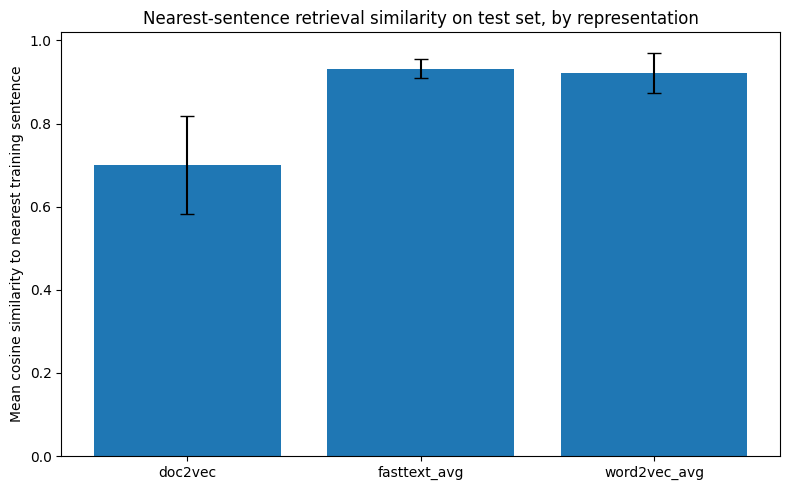

In [22]:

fig, ax = plt.subplots(figsize=(8, 5))
plot_summary = summary[summary["split"] == "test"]
ax.bar(plot_summary["representation"], plot_summary["mean"], yerr=plot_summary["std"], capsize=5)
ax.set_ylabel("Mean cosine similarity to nearest training sentence")
ax.set_title("Nearest-sentence retrieval similarity on test set, by representation")
plt.tight_layout()
plt.show()


## 10. Save all models and results

In [23]:

print("Models saved in:", MODELS_DIR.resolve())
for p in MODELS_DIR.glob("*"):
    print(" -", p.name)

print("\nResults saved in:", RESULTS_DIR.resolve())
for p in RESULTS_DIR.glob("*"):
    print(" -", p.name)


Models saved in: /Users/mjgandhi2305/Semester_7/ILLM/A5/models
 - fasttext_hindi.model.wv.vectors_ngrams.npy
 - fasttext_hindi.model
 - doc2vec_hindi.model
 - word2vec_hindi.model

Results saved in: /Users/mjgandhi2305/Semester_7/ILLM/A5/results
 - nearest_sentence_retrieval.csv
 - kmeans_cluster_top_words.csv


## 11. Summary / discussion (fill in after running)

Typical patterns to look for once this notebook has been executed end-to-end on the real
1M-sentence Hindi corpus:

- **Word2Vec vs. fastText nearest neighbours**: fastText's character n-gram component tends to
  group **morphologically related** forms (shared prefixes/suffixes, common in Hindi inflection)
  more consistently than Word2Vec, which relies purely on distributional (context) similarity.
  fastText should also rarely, if ever, fail to produce a vector for a dev/test word, whereas
  Word2Vec-average sentence vectors can degrade (or collapse to zero) for sentences containing
  many out-of-vocabulary words.
- **K-Means clusters**: with a good embedding space, clusters should roughly correspond to
  coherent semantic/syntactic groups (e.g. numerals together, function words together, place
  names together, etc.) — inspect `cluster_top_words` in Section 6 and note which clusters look
  most/least coherent.
- **Nearest-sentence retrieval**: Doc2Vec's inferred vectors are optimized end-to-end for
  whole-sentence similarity, so they often retrieve more **topically coherent** matches than
  simply averaging word vectors, which can be dominated by a few high-magnitude or high-frequency
  words and lose sentence-level structure (word order, negation, etc. are invisible to a bag-of-
  vectors average).
- **Mean cosine similarity (Section 9)**: compare the bar heights across the three
  representations — a consistently higher mean for one representation suggests that embedding
  space packs the corpus's sentences more tightly / has less spread, which is not automatically
  "better" without also inspecting the qualitative examples in Section 8.

Replace this cell with your own numeric observations (referencing the tables/plots above) once
you've executed the notebook on your data.
